In [1]:
import os
import itertools
import math
from shapely.geometry import Polygon
from shapely.affinity import translate
from shapely.ops import unary_union
import matplotlib.pyplot as plt


# ===============================
# GEOMETRY SAFETY
# ===============================

def clean(poly):
    try:
        poly = poly.buffer(0)
    except:
        pass
    return poly


# ===============================
# LOAD POLYGONS FROM DESIGN FOLDER
# ===============================

def to_poly(coords):
    return clean(Polygon(coords))


def process_design_folder(folder):
    shape_items = []

    for file in os.listdir(folder):
        if not file.endswith(".txt"):
            continue

        path = os.path.join(folder, file)

        with open(path) as f:
            coords = []
            for line in f:
                x,y = map(float, line.strip().split(","))
                coords.append((x,y))

        poly = to_poly(coords)
        shape_items.append(poly)

    return shape_items


# ===============================
# DROP PIECE SAFELY
# ===============================

def drop_piece(poly, placed_polys, step=0.5):

    poly = clean(poly)

    if not placed_polys:
        miny = poly.bounds[1]
        return translate(poly, 0, -miny)

    base = [clean(p) for p in placed_polys]
    base_union = unary_union(base)

    y = 0
    last_good = poly

    for _ in range(2000):

        moved = translate(poly, 0, y)

        if moved.intersects(base_union):
            return clean(last_good)

        last_good = moved
        y += step

    return clean(last_good)


# ===============================
# PLACE ROW (SIDE BY SIDE SLIDE)
# ===============================

def place_row(polys, placed_polys, strip_width):

    x_cursor = 0
    shifted = []

    for p in polys:
        minx = p.bounds[0]
        moved = translate(p, x_cursor - minx, 0)

        shifted.append(moved)

        x_cursor += moved.bounds[2] - moved.bounds[0]

    total_width = x_cursor

    if total_width > strip_width:
        return None

    # drop onto contour
    final_row = []

    for p in shifted:
        dropped = drop_piece(p, placed_polys + final_row)
        final_row.append(clean(dropped))

    return final_row


# ===============================
# SCORE ROW
# ===============================

def score_row(row, strip_width):

    union = unary_union(row)
    used = union.area

    minx, miny, maxx, maxy = union.bounds
    width = maxx - minx
    height = maxy - miny

    rect_area = width * height
    empty = rect_area - used

    score = used - empty * 0.3
    return score


# ===============================
# BUILD BEST ROW
# ===============================

def build_best_row(remaining, placed_polys, strip_width, max_stack=5):

    best_score = -1e9
    best_layout = None
    best_used = None

    print("searching rows...")

    for r in range(1, min(max_stack, len(remaining)) + 1):

        combos = list(itertools.combinations(range(len(remaining)), r))

        for combo in combos[:80]:

            stack = [remaining[i] for i in combo]

            for perm in list(itertools.permutations(stack))[:6]:

                layout = place_row(list(perm), placed_polys, strip_width)

                if layout is None:
                    continue

                score = score_row(layout, strip_width)

                if score > best_score:
                    best_score = score
                    best_layout = layout
                    best_used = combo

    if best_layout is None:
        return None, None

    print("best row score:", round(best_score,2))
    return best_layout, best_used


# ===============================
# RENDER
# ===============================

def render_all(polys, strip_width):

    plt.figure(figsize=(12,6))

    for p in polys:
        x,y = p.exterior.xy
        plt.plot(x,y,'k')

    plt.xlim(0, strip_width)
    plt.gca().invert_yaxis()
    plt.title("FINAL")
    plt.show()


# ===============================
# ENGINE
# ===============================

def run_engine(shape_items, strip_width):

    remaining = shape_items[:]
    placed = []

    row_id = 1

    while remaining:

        print("\n--- ROW", row_id, "---")

        row, used_idx = build_best_row(remaining, placed, strip_width)

        if row is None:
            print("no more rows possible")
            break

        for p in row:
            placed.append(clean(p))

        # remove used pieces
        for i in sorted(used_idx, reverse=True):
            remaining.pop(i)

        row_id += 1

    print("\nFINAL PLACEMENT")
    render_all(placed, strip_width)



FINAL PLACEMENT


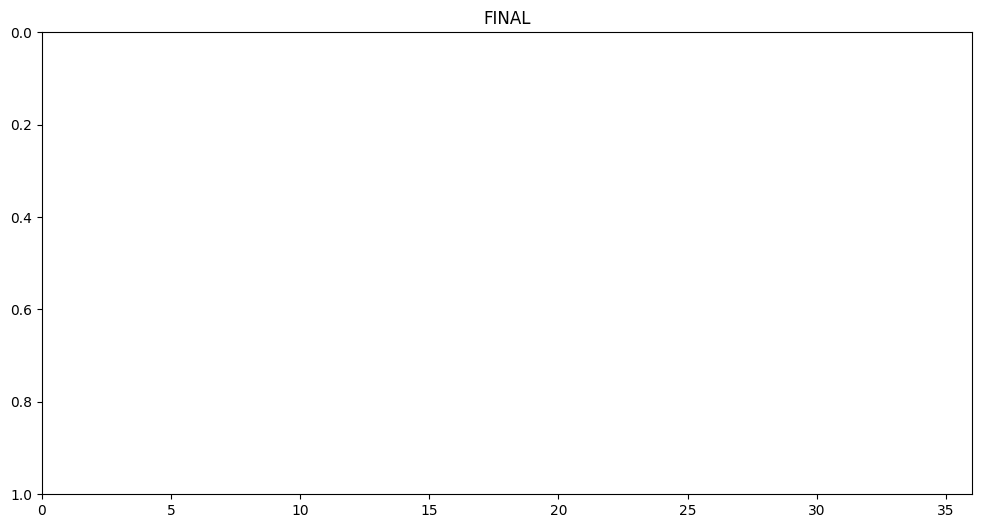

In [2]:
design_folder = "JK-123"   # your folder
STRIP_WIDTH = 36

shape_items = process_design_folder(design_folder)
run_engine(shape_items, STRIP_WIDTH)

In [3]:
shape_items

[]